# Home Work 01

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split # to split data into train and test
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score # to evaluate the performance of the model
import warnings # to not print warnings 
warnings.filterwarnings("ignore")

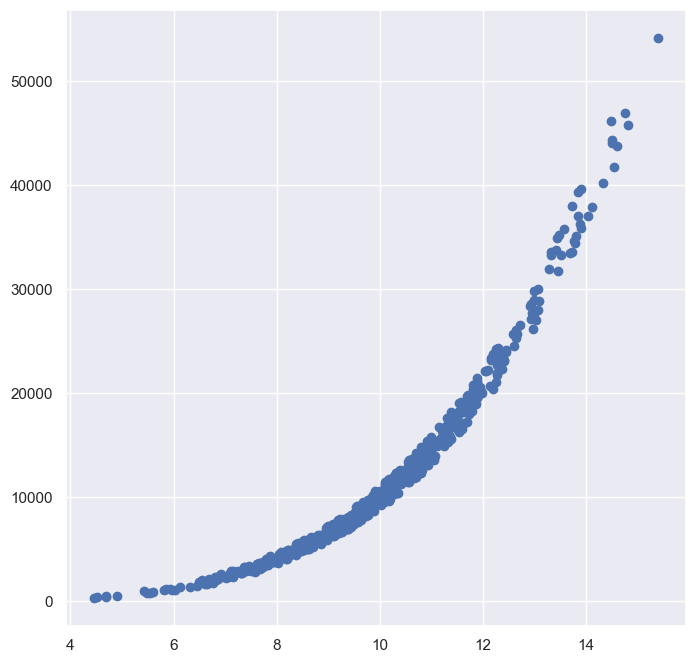

In [15]:
sns.set(color_codes=True)
plt.rcParams["figure.figsize"] = [12,12]

plt.figure(figsize=(8,8))

np.random.seed(0)
#DataSet_Given by :  y = f(x)  avec f(x) = x^4 + bx^3 + c 

x = np.random.normal(10, 2, 500)
y = x ** 4 + np.random.uniform(-1, 1,500)*(x ** 3) + np.random.uniform(0, 1,500)

plt.scatter(x,y)
plt.show()


## Plot different degrees of polynomial regression

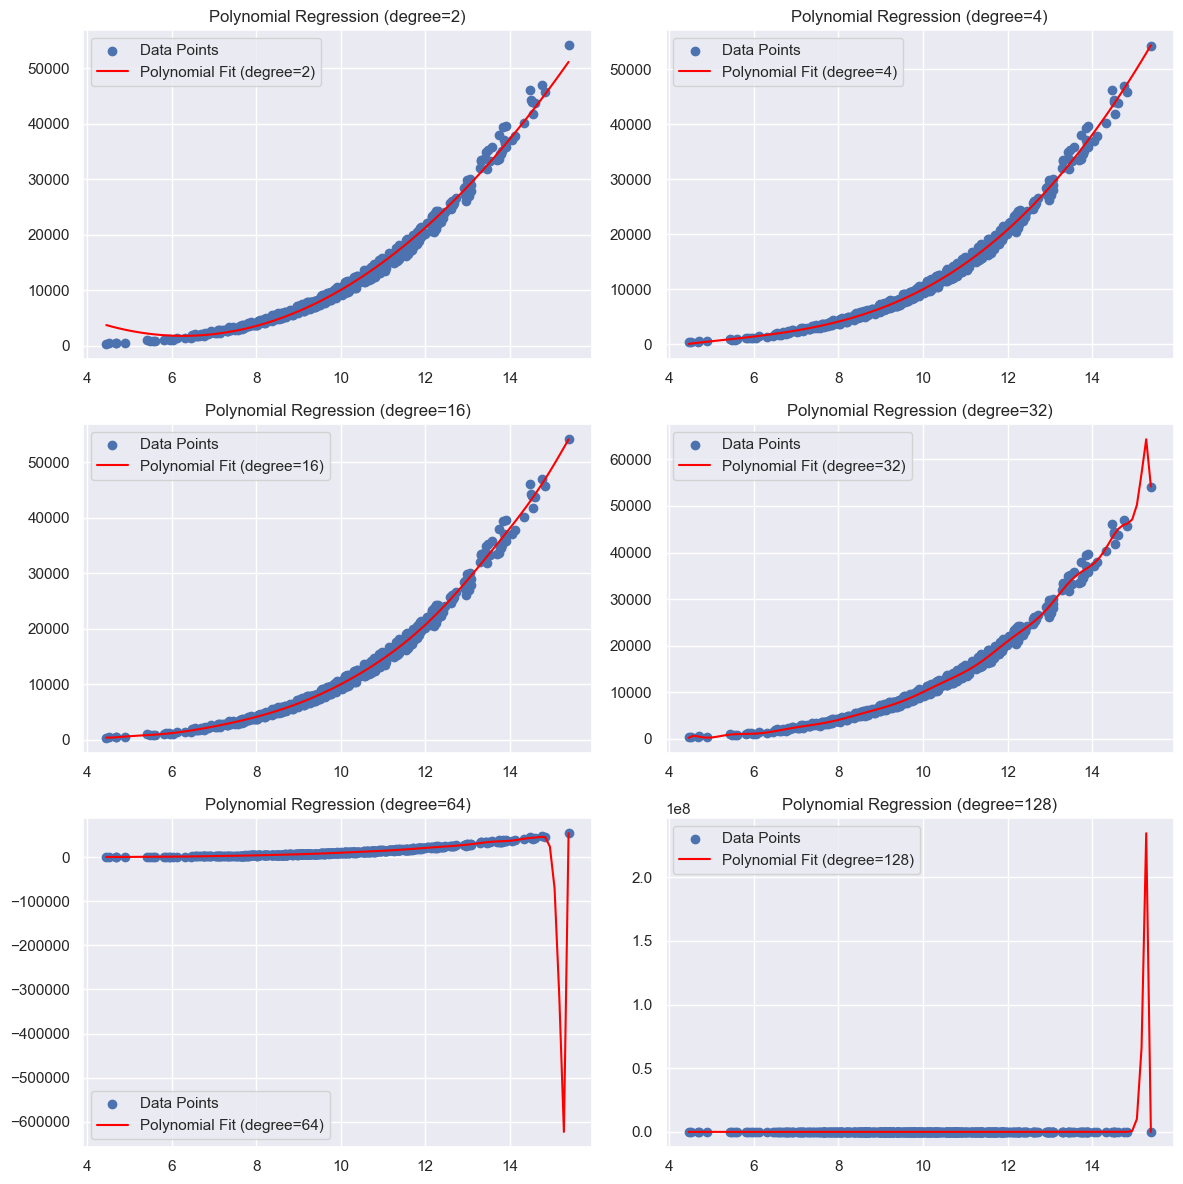

In [ ]:
# try different degrees of polynomial regression
degrees = [2, 4, 16, 32, 64, 128]
plt.figure(figsize=(12, 12))
for i, degree in enumerate(degrees):
    coefficients = np.polyfit(x, y, degree)
    polynomial = np.poly1d(coefficients)
    x_poly = np.linspace(min(x), max(x), 100)
    y_poly = polynomial(x_poly)
    
    plt.subplot(3, 2, i+1)
    plt.scatter(x, y, label='Data Points')
    plt.plot(x_poly, y_poly, color='red', label=f'Polynomial Fit (degree={degree})')
    plt.legend()
    plt.title(f'Polynomial Regression (degree={degree})')
plt.tight_layout()
plt.show()

    

According to the plots, the best degree for polynomial regression seems to be around 4

## Calculate the cost function

To be able to evaluate the performance of the model, and choose a safe range of polynomial degrees,  cost functions such as MSE, MAE and R2 score. We will then plot the cost functions for different degrees of polynomial regression to see how they change with increasing degree.

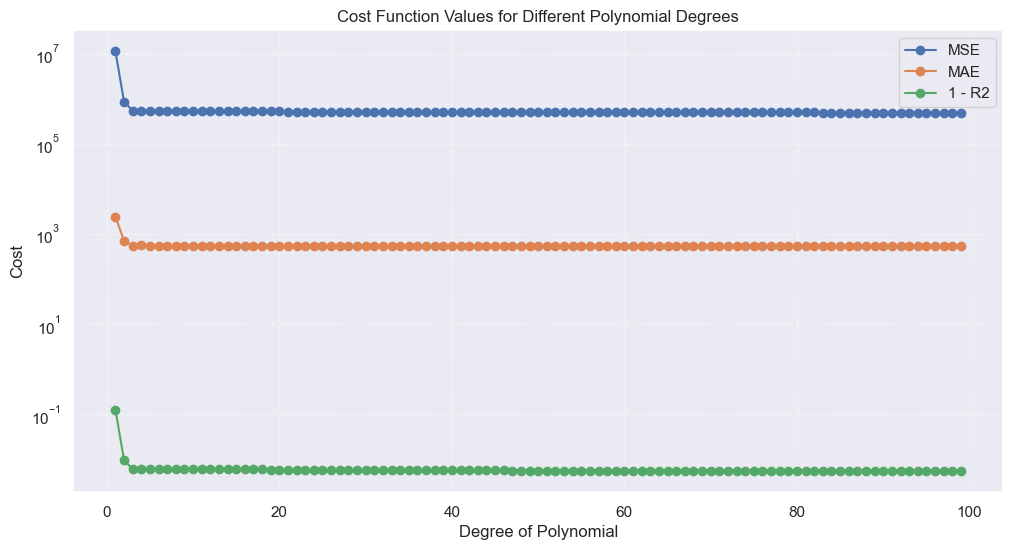

In [ ]:
# choose a safe range of polynomial degrees 
degrees = range(1, 100)  

cost_functions = {
    "MSE": mean_squared_error,
    "MAE": mean_absolute_error,
    "1 - R2": lambda y_true, y_pred: 1 - r2_score(y_true, y_pred),
}

cost_values = {name: [] for name in cost_functions.keys()}

for degree in degrees:
    try:
        # fit polynomial of given degree
        coeffs = np.polyfit(x, y, degree)
        poly = np.poly1d(coeffs)
        y_pred = poly(x)

        for name, func in cost_functions.items():
            cost = func(y, y_pred)
            cost_values[name].append(cost)
    except Exception as e:
        for name in cost_values.keys():
            cost_values[name].append(np.nan)
        print(f"Degree {degree} failed: {e}")

plt.figure(figsize=(12, 6))
for name, values in cost_values.items():
    plt.plot(list(degrees), values, marker="o", label=name)

plt.xlabel("Degree of Polynomial")
plt.ylabel("Cost")
plt.yscale("log")  
plt.title("Cost Function Values for Different Polynomial Degrees")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.show()


Here we used the same dataset to calculate the different cost function as we can see, the cost value keep decreasing as the degree of the polynomial increase, this is a sign of overfitting, the model is fitting the noise in the data rather than the underlying pattern. This is why we see such a significant decrease in cost values as the degree increases, especially for MSE and MAE. The 1 - R2 also shows a similar trend, indicating that the model's performance is improving on the training data but may not generalize well to unseen data.

that why next we will use a test set to evaluate the performance of the model and to see how it generalizes to new data.

## Train vs test cost for all cost functions


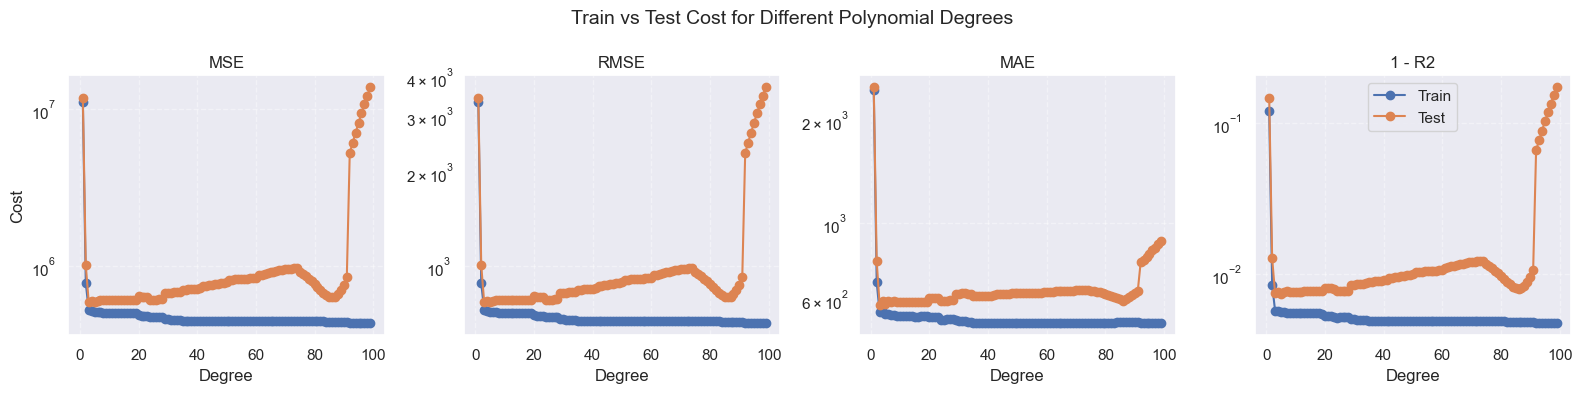

In [18]:


# split data into train and test once
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

# define the same cost functions as before
cost_functions = {
    "MSE": mean_squared_error,
    "RMSE": lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred)),
    "MAE": mean_absolute_error,
    "1 - R2": lambda y_true, y_pred: 1 - r2_score(y_true, y_pred),
}

# degrees to analyze
degrees = range(1, 100)

# store train and test costs for each function
train_costs = {name: [] for name in cost_functions.keys()}
test_costs = {name: [] for name in cost_functions.keys()}

for d in degrees:
    try:
        coeffs = np.polyfit(x_train, y_train, d)
        poly = np.poly1d(coeffs)

        y_train_pred = poly(x_train)
        y_test_pred = poly(x_test)

        for name, func in cost_functions.items():
            train_costs[name].append(func(y_train, y_train_pred))
            test_costs[name].append(func(y_test, y_test_pred))
    except Exception as e:
        for name in cost_functions.keys():
            train_costs[name].append(np.nan)
            test_costs[name].append(np.nan)
        print(f"Degree {d} failed: {e}")

# plot: one subplot per cost function, showing train vs test cost
n_costs = len(cost_functions)
fig, axes = plt.subplots(1, n_costs, figsize=(4 * n_costs, 4), sharex=True)

if n_costs == 1:
    axes = [axes]

for ax, name in zip(axes, cost_functions.keys()):
    ax.plot(list(degrees), train_costs[name], marker="o", label="Train")
    ax.plot(list(degrees), test_costs[name], marker="o", label="Test")
    ax.set_title(name)
    ax.set_xlabel("Degree")
    ax.grid(True, linestyle="--", alpha=0.4)

    vals = np.array(train_costs[name] + test_costs[name], dtype=float)
    if np.all(vals > 0):
        ax.set_yscale("log")

axes[0].set_ylabel("Cost")
fig.suptitle("Train vs Test Cost for Different Polynomial Degrees", fontsize=14)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

Here, since we used the test set, we see that the cost functions start to diverge at a certain degree, indicating overfitting. The train cost continues to decrease as the degree increases, while the test cost starts to increase after a certain point, showing that the model is fitting the noise in the training data rather than the underlying pattern.

## Final decision on best degree
According to the plots, the best degree seems to be around 4, as it has the lowest test cost across all cost functions. Degrees higher than 4 show a significant increase in test cost, indicating overfitting.